In [1]:
import sys
sys.path.insert(0, "/home/aryan/hiv-latency-sc/plotting")
import config
print("config loaded:", config.CHECKPOINTS) 

config loaded: /scratch/maid/DP2_PBMC/checkpoints


In [2]:
import scanpy as sc, config

kept = sorted(sc.read_h5ad(config.CHECKPOINTS/"02_filtered.h5ad", backed="r").obs["sample"].unique())
print(len(kept), "samples kept:", kept)

26 samples kept: ['DEAB_Wk0', 'DEAB_Wk136', 'DEAB_Wk16', 'DEAB_Wk192', 'DEAB_Wk304', 'DEAB_Wk4', 'DEAB_Wk72', 'DEG2_Wk0', 'DEG2_Wk16', 'DEG2_Wk192', 'DEG2_Wk304', 'DEG2_Wk72', 'DEL5_Wk0', 'DEL5_Wk16', 'DEL5_Wk192', 'DEL5_Wk304', 'DEL5_Wk72', 'KI6_Wk192', 'PZB_Wk0', 'PZB_Wk136', 'PZB_Wk4', 'PZB_Wk72', 'T623_Wk0', 'T623_Wk128', 'T623_Wk64', 'T623_Wk8']


In [4]:
import sys; sys.path.insert(0, "/home/aryan/hiv-latency-sc/plotting")
import config, pandas as pd
consensus = pd.read_csv(config.CHECKPOINTS/"consensus_peaks.bed", sep="\t",
                           header=None, names=["Chromosome","Start","End"])
print(f"consensus reloaded: {len(consensus):,} peaks")   # 233,943

consensus reloaded: 233,943 peaks


In [5]:
import snapatac2 as snap
print("snap loaded:", snap.__version__)

snap loaded: 2.10.0


/home/aryan/hiv-latency-sc/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
import scanpy, anndata, pandas
print("scanpy", scanpy.__version__, "| anndata", anndata.__version__, "| pandas", pandas.__version__)
a = scanpy.read_h5ad(config.CHECKPOINTS/"02_filtered.h5ad", backed="r")
print("RNA object still loads:", a.shape)   # want (163951, 24051)

/tmp/ipykernel_2476633/4237774816.py:2: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('scanpy')` instead
  print("scanpy", scanpy.__version__, "| anndata", anndata.__version__, "| pandas", pandas.__version__)
/tmp/ipykernel_2476633/4237774816.py:2: FutureWarning: `__version__` is deprecated, use `importlib.metadata.version('anndata')` instead.
  print("scanpy", scanpy.__version__, "| anndata", anndata.__version__, "| pandas", pandas.__version__)


scanpy 1.12.4 | anndata 0.13.4 | pandas 2.3.3
RNA object still loads: (163951, 24051)


In [7]:
print([g for g in dir(snap.genome) if not g.startswith("_")])

['Callable', 'Decompress', 'GRCh37', 'GRCh38', 'GRCm38', 'GRCm39', 'Genome', 'Path', 'annotations', 'hg19', 'hg38', 'load', 'mm10', 'mm39']


In [9]:
import pandas as pd
fai = pd.read_csv(
    "/scratch/references/refdata-cellranger-arc-Mmul_10-2023-A/fasta/genome.fa.fai",
    sep="\t", header=None, usecols=[0,1], names=["chrom", "length"], dtype={"chrom":str}
)
chrom_sizes = dict(zip(fai["chrom"], fai["length"]))

print(f"{len(chrom_sizes)} contigs total")
main = [str(i) for i in range(1, 21)] + ["X", "Y"]
print(f"main chromosomes present:", [c for c in main if c in chrom_sizes])
print("example: chr1 length:", f"{chrom_sizes['1']:,} bp")

2939 contigs total
main chromosomes present: ['1', '2', '3', '4', '5', '6', '7', '8', '9', '10', '11', '12', '13', '14', '15', '16', '17', '18', '19', '20', 'X', 'Y']
example: chr1 length: 223,616,942 bp


In [10]:
main_chroms = [str(i) for i in range(1, 21)] + ["X", "Y"]
on_main = consensus["Chromosome"].astype(str).isin(main_chroms).sum()
print(f"{on_main:,} / {len(consensus):,} consensus peaks on main chromosomes ({on_main/len(consensus):.1%})")

231,794 / 233,943 consensus peaks on main chromosomes (99.1%)


In [11]:
main_chroms = [str(i) for i in range(1,21)] + ["X","Y"]
consensus_main = consensus[consensus["Chromosome"].astype(str).isin(main_chroms)].copy()
consensus_main = consensus_main.sort_values(["Chromosome","Start"]).reset_index(drop=True)

# overwrite the saved bed with the trimmed set (this is what quantification will use)
out = config.CHECKPOINTS / "consensus_peaks.bed"
consensus_main[["Chromosome","Start","End"]].to_csv(out, sep="\t", header=False, index=False)
print(f"trimmed to main chromosomes: {len(consensus_main):,} peaks -> {out}")

trimmed to main chromosomes: 231,794 peaks -> /scratch/maid/DP2_PBMC/checkpoints/consensus_peaks.bed


In [12]:
import snapatac2 as snap
import scanpy as sc, anndata as ad
from pathlib import Path

RAW = Path("/scratch/maid/DP2_PBMC/PBMC_rawData")
CONSENSUS = str(config.CHECKPOINTS / "consensus_peaks.bed")

# kept barcodes per sample, from the RNA object (the alignment anchor)
rna = sc.read_h5ad(config.CHECKPOINTS / "02_filtered.h5ad", backed="r")
kept_by_sample = {s: set(rna.obs_names[rna.obs["sample"] == s]) for s in rna.obs["sample"].unique()}

dev_samples = ["DEAB_Wk16", "DEG2_Wk16", "DEL5_Wk16"]
per_sample = []
for s in dev_samples:
    # 1. import fragments with our macaque chrom_sizes
    a = snap.pp.import_fragments(str(RAW/s/"atac_fragments.tsv.gz"),
                                 chrom_sizes=chrom_sizes, sorted_by_barcode=False)
    # 2. prefix barcodes to match RNA, restrict to kept cells
    a.obs_names = [s + "_" + bc for bc in a.obs_names]
    keep = [bc for bc in a.obs_names if bc in kept_by_sample[s]]
    print(f"  {s}: imported {a.n_obs:,} barcodes | matched {len(keep):,} of "
          f"{len(kept_by_sample[s]):,} kept RNA cells")
    a = a[keep].copy()
    # 3. count fragments in consensus peaks
    pm = snap.pp.make_peak_matrix(a, peak_file=CONSENSUS)
    per_sample.append(pm)

atac_dev = ad.concat(per_sample)
print(f"\n[DEV] ATAC peak matrix: {atac_dev.shape[0]:,} cells x {atac_dev.shape[1]:,} peaks")

  DEAB_Wk16: imported 61,480 barcodes | matched 8,557 of 8,571 kept RNA cells
  DEG2_Wk16: imported 65,171 barcodes | matched 7,725 of 7,800 kept RNA cells
  DEL5_Wk16: imported 67,932 barcodes | matched 3,779 of 3,781 kept RNA cells

[DEV] ATAC peak matrix: 20,061 cells x 231,794 peaks


In [13]:
print("matrix dtype:", atac_dev.X.dtype)
print("total fragments counted:", int(atac_dev.X.sum()))
print("median peaks detected per cell:", int((atac_dev.X > 0).sum(axis=1).A1 if hasattr(atac_dev.X,'A1') else (atac_dev.X>0).sum(1)).mean() if False else 'see below')
import numpy as np
peaks_per_cell = np.asarray((atac_dev.X > 0).sum(axis=1)).ravel()
print(f"peaks detected per cell: median {np.median(peaks_per_cell):.0f}, "
      f"mean {peaks_per_cell.mean():.0f}")

matrix dtype: uint32
total fragments counted: 100133157
median peaks detected per cell: see below
peaks detected per cell: median 2810, mean 3885


In [14]:
import scipy.sparse as sp
print("sparse?", sp.issparse(atac_dev.X))
if sp.issparse(atac_dev.X):
    density = atac_dev.X.nnz / (atac_dev.shape[0]*atac_dev.shape[1])
    print(f"density: {density*100:.2f}% nonzero  ->  stored sparse, memory-safe")

sparse? True
density: 1.68% nonzero  ->  stored sparse, memory-safe


In [21]:
import muon as mu
import scanpy as sc
import anndata as ad
import config
anndata.settings.allow_write_nullable_strings = True

rna = sc.read_h5ad(config.CHECKPOINTS / "03_pca.h5ad")
atac = sc.read_h5ad(config.CHECKPOINTS / "05_atac_peaks.h5ad")
print("RNA :", rna.shape)
print("ATAC :", atac.shape)

#keeping only cells that are present in both datasets
shared = rna.obs_names.intersection(atac.obs_names)
print(f"shared cells: {len(shared):,} / {rna.shape[0]:,} RNA | {atac.shape[0]:,} ATAC")
rna = rna[shared].copy()
atac = atac[shared].copy()

RNA : (163951, 2000)
ATAC : (163130, 231794)
shared cells: 163,130 / 163,951 RNA | 163,130 ATAC


In [22]:
mdata = mu.MuData({"rna": rna, "atac": atac})
print(mdata)

MuData object with n_obs × n_vars = 163130 × 233794
  2 modalities
    rna:	163130 × 2000
      obs:	'sample', 'animal', 'week', 'group', 'batch', 'n_genes_by_counts', 'log1p_n_genes_by_counts', 'total_counts', 'log1p_total_counts', 'total_counts_mt', 'log1p_total_counts_mt', 'pct_counts_mt', 'TSS.enrichment', 'nucleosome_signal', 'keep_reason', 'n_genes', 'doublet_score', 'predicted_doublet', 'leiden'
      var:	'gene_ids', 'feature_types', 'genome', 'interval', 'mt', 'n_cells_by_counts', 'mean_counts', 'log1p_mean_counts', 'pct_dropout_by_counts', 'total_counts', 'log1p_total_counts', 'n_cells', 'highly_variable', 'highly_variable_rank', 'means', 'variances', 'variances_norm', 'highly_variable_nbatches', 'mean', 'std'
      uns:	'hvg', 'keep_reason_colors', 'leiden', 'log1p', 'neighbors', 'pca', 'scrublet', 'stage_01', 'stage_02', 'stage_03'
      obsm:	'X_pca', 'X_pca_harmony'
      varm:	'PCs'
      layers:	'counts', None
      obsp:	'connectivities', 'distances'
    atac:	163130 ×

In [25]:
from muon import atac as ac

atac = mdata["atac"]

ac.pp.tfidf(atac, scale_factor=1e4)

ac.tl.lsi(atac, n_comps=50)

print("LSI done:", atac.obsm["X_lsi"].shape)

LSI done: (163130, 50)


In [27]:
import numpy as np

# Calculating the depth of each cell
depth = np.asarray(atac.X.sum(1)).ravel() if atac.X is not None else atac.obs["n_fragment"].values

depth = atac.obs["n_fragment"].values
for i in range(5):
    r = np.corrcoef(atac.obsm["X_lsi"][:,i], depth)[0, 1]
    print(f"LSI component {i}: correlation with depth = {r:.3f}")


LSI component 0: correlation with depth = -0.266
LSI component 1: correlation with depth = -0.084
LSI component 2: correlation with depth = 0.044
LSI component 3: correlation with depth = 0.010
LSI component 4: correlation with depth = -0.588


In [28]:
import numpy as np
depth = atac.obs["n_fragment"].values
cors = np.array([np.corrcoef(atac.obsm["X_lsi"][:, i], depth)[0,1] for i in range(50)])
print("components with |depth correlation| > 0.4:")
for i in np.where(np.abs(cors) > 0.4)[0]:
    print(f"  comp {i}: r = {cors[i]:.3f}")
print(f"\nmax |r| = {np.abs(cors).max():.3f} at comp {np.abs(cors).argmax()}")

components with |depth correlation| > 0.4:
  comp 4: r = -0.588

max |r| = 0.588 at comp 4


In [29]:
keep_comps = [i for i in range(50) if i != 4]
atac.obsm["X_lsi_clean"] = atac.obsm["X_lsi"][:,keep_comps]
print("Cleaned LSI:", atac.obsm["X_lsi_clean"].shape)

Cleaned LSI: (163130, 49)


In [30]:
import harmonypy, numpy as np

atac = mdata["atac"]

# batch labels 
atac.obs["batch"] = mdata["rna"].obs["batch"].values

ho = harmonypy.run_harmony(
    atac.obsm["X_lsi_clean"].astype(np.float64),
    atac.obs, vars_use=["batch"])
Z = ho.Z_corr                                    # your version: (cells, comps), no .T
assert Z.shape == atac.obsm["X_lsi_clean"].shape, f"{Z.shape} vs {atac.obsm['X_lsi_clean'].shape}"
atac.obsm["X_lsi_harmony"] = np.asarray(Z)
print("ATAC harmony done:", atac.obsm["X_lsi_harmony"].shape)   # 163130 x 49

2026-10-25 23:54:10,236 - harmonypy - INFO - Running Harmony
2026-10-25 23:54:10 - INFO - Running Harmony
2026-10-25 23:54:10,237 - harmonypy - INFO -   Parameters:
2026-10-25 23:54:10 - INFO -   Parameters:
2026-10-25 23:54:10,237 - harmonypy - INFO -     max_iter_harmony: 10
2026-10-25 23:54:10 - INFO -     max_iter_harmony: 10
2026-10-25 23:54:10,238 - harmonypy - INFO -     max_iter_kmeans: 4
2026-10-25 23:54:10 - INFO -     max_iter_kmeans: 4
2026-10-25 23:54:10,238 - harmonypy - INFO -     epsilon_cluster: 0.001
2026-10-25 23:54:10 - INFO -     epsilon_cluster: 0.001
2026-10-25 23:54:10,238 - harmonypy - INFO -     epsilon_harmony: 0.01
2026-10-25 23:54:10 - INFO -     epsilon_harmony: 0.01
2026-10-25 23:54:10,239 - harmonypy - INFO -     nclust: 100
2026-10-25 23:54:10 - INFO -     nclust: 100
2026-10-25 23:54:10,239 - harmonypy - INFO -     block_size: 0.05
2026-10-25 23:54:10 - INFO -     block_size: 0.05
2026-10-25 23:54:10,239 - harmonypy - INFO -     lamb: dynamic (alpha=0.

ATAC harmony done: (163130, 49)


In [31]:
mdata["rna"].obsm["X_pca_harmony"]
mdata["atac"].obsm["X_lsi_harmony"]

sc.pp.neighbors(mdata["rna"], use_rep="X_pca_harmony", n_pcs=config.N_PCS, random_state=config.SEED)
sc.pp.neighbors(mdata["atac"], use_rep="X_lsi_harmony", random_state=config.SEED)

#WNN
mu.pp.neighbors(mdata, key_added="wnn")
print("wnn done")


wnn done


In [33]:

# cluster on the JOINT (WNN) graph
sc.tl.leiden(mdata, neighbors_key="wnn", resolution=1.0, key_added="wnn_leiden",
             random_state=config.SEED, flavor="igraph", n_iterations=2)

# UMAP 
mu.tl.umap(mdata, neighbors_key="wnn", random_state=config.SEED)

print("WNN clusters:", mdata.obs["wnn_leiden"].nunique())
print(mdata.obs["wnn_leiden"].value_counts().sort_index())

WNN clusters: 32
wnn_leiden
0     12104
1      3942
2      4140
3      3684
4      4226
5     10511
6      3474
7     15862
8      5264
9     13039
10      139
11     3295
12     2986
13     1158
14     1610
15     9115
16     2894
17    13502
18     4592
19     3598
20     3068
21    12326
22     2187
23     2384
24     1568
25     8875
26     4816
27     2254
28      607
29      641
30     3089
31     2180
Name: count, dtype: int64


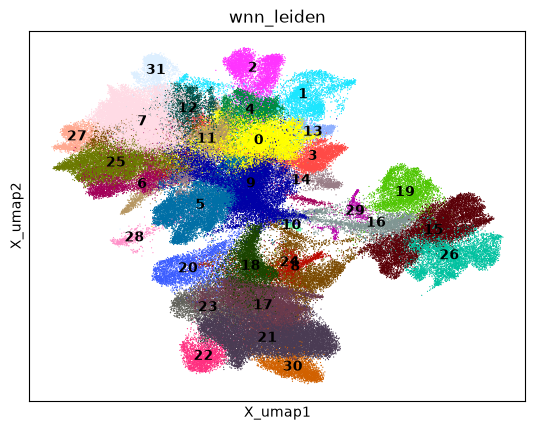

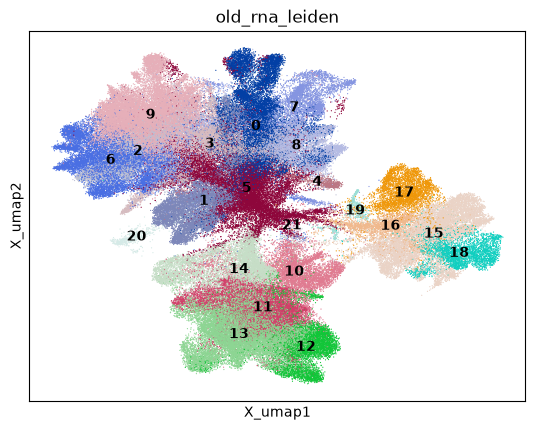

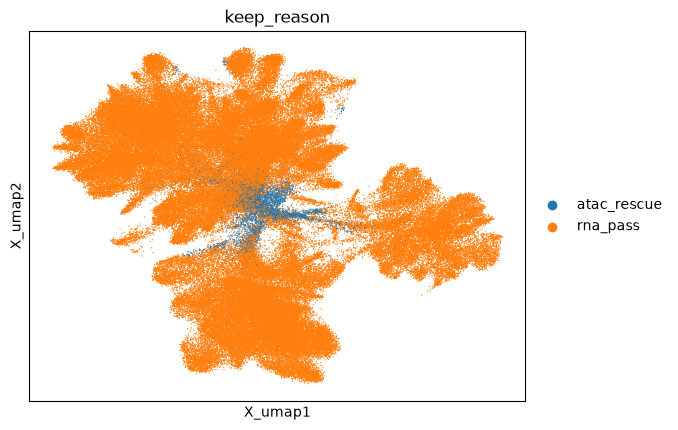

In [34]:
import muon as mu

# carry RNA-side labels onto the MuData for comparison on the joint UMAP
mdata.obs["old_rna_leiden"] = mdata["rna"].obs["leiden"].values
mdata.obs["keep_reason"]    = mdata["rna"].obs["keep_reason"].values

mu.pl.umap(mdata, color=["wnn_leiden"], size=3, legend_loc="on data")
mu.pl.umap(mdata, color=["old_rna_leiden"], size=3, legend_loc="on data")
mu.pl.umap(mdata, color=["keep_reason"], size=3)

In [ ]:
import matplotlib.pyplot as plt
sc.settings.set_figure_params(dpi=150, dpi_save=300, figsize=(7,6), frameon=False)

/tmp/ipykernel_2476633/1685705596.py:2: FutureWarning: The method set_figure_params is deprecated and will be removed in the future. Use :func:`scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi=150, dpi_save=300, figsize=(7,6), frameon=False)


In [41]:
%pip install colorcet

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 262.3/262.3 kB 6.6 MB/s eta 0:00:00a 0:00:01
Note: you may need to restart the kernel to use updated packages.


/home/aryan/hiv-latency-sc/.venv/lib/python3.12/site-packages/muon/pl.py:237: FutureWarning: Argument `save` is deprecated and will be removed in a future version. Use `sc.pl.plot(show=False).figure.savefig()` instead.
  retval = sc.pl.embedding(ad, basis=basis_mod, color=color, **kwargs)


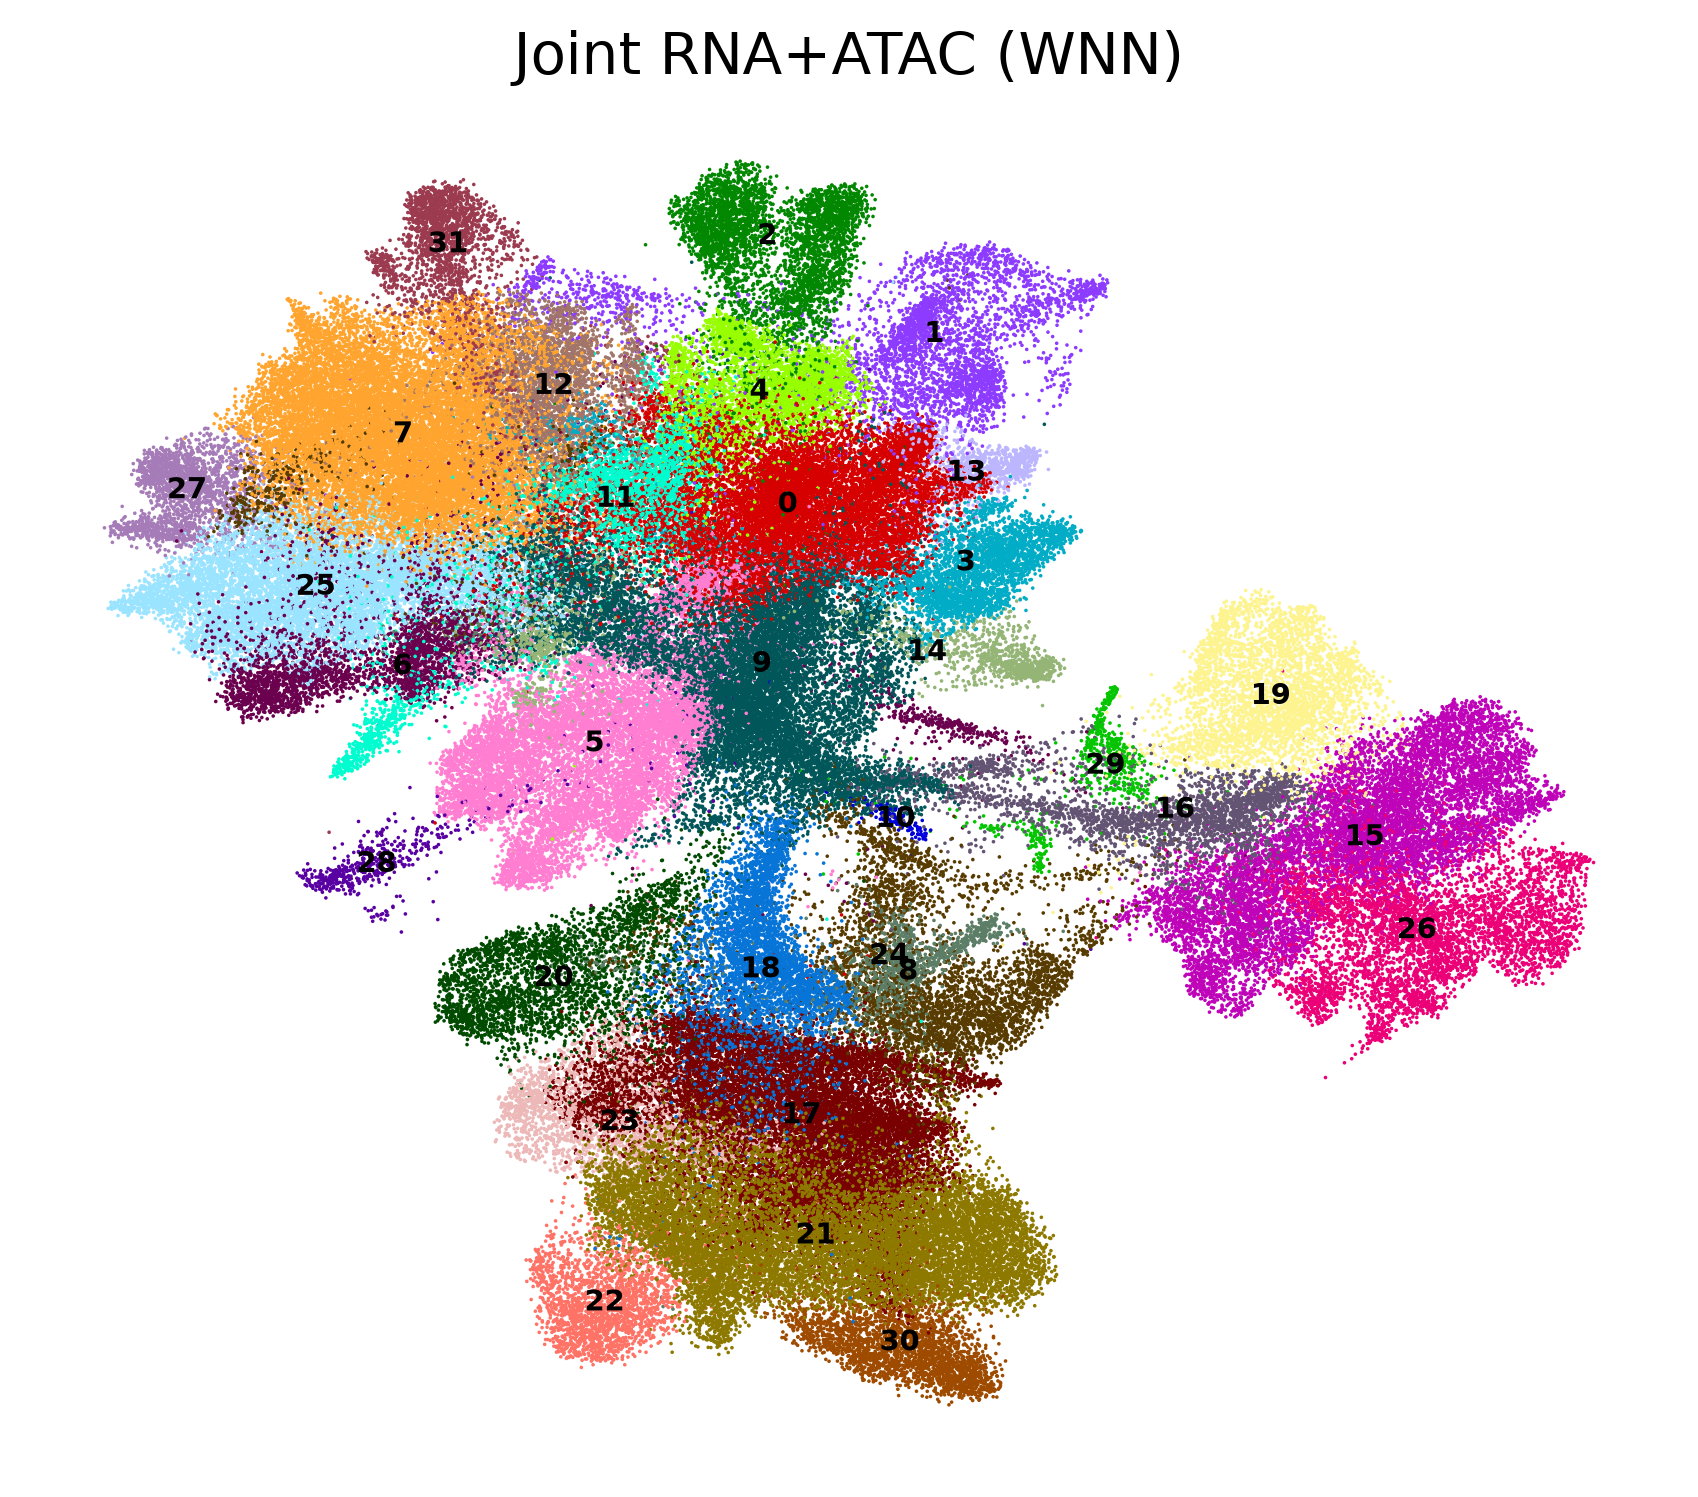

In [42]:
import colorcet as cc   
mu.pl.umap(mdata, color="wnn_leiden", palette=cc.glasbey,
           legend_loc="on data", legend_fontsize=7,
           title="Joint RNA+ATAC (WNN)", size=3, save="_wnn_clusters.png")

In [35]:
import pandas as pd
# where did old cluster 5's cells go in the WNN clustering?
c5 = mdata.obs[mdata.obs["old_rna_leiden"] == "5"]
print(f"old cluster 5: {len(c5):,} cells")
print("now distributed across WNN clusters:")
print(c5["wnn_leiden"].value_counts().sort_values(ascending=False).head(10))

old cluster 5: 15,005 cells
now distributed across WNN clusters:
wnn_leiden
9     10715
5       933
16      514
0       474
18      298
25      222
8       214
11      213
2       212
3       197
Name: count, dtype: int64


In [36]:
import pandas as pd

obs = mdata["rna"].obs   # has animal, week, group, batch per cell

# animal x timepoint cell counts (the structured table you asked for)
tbl = pd.crosstab(obs["animal"], obs["week"])
print("Cells per animal x timepoint:")
print(tbl)
print("\nrow totals (per animal):")
print(tbl.sum(axis=1).sort_values(ascending=False))
print("\ncolumn totals (per timepoint):")
print(tbl.sum(axis=0))

Cells per animal x timepoint:
week     Wk0   Wk4   Wk8  Wk16  Wk72  Wk136  Wk192  Wk304
animal                                                   
DEAB    3071  2972     0  8557  6272   9121   9983   9111
DEG2    9478     0     0  7725  8846      0   7654   8125
DEL5    6677     0     0  3779  5652      0   2960   3701
KI6        0     0     0     0     0      0   2439      0
PZB     3757  7746     0     0  4729   5979      0      0
T623    6451     0  6475     0  6119   5751      0      0

row totals (per animal):
animal
DEAB    49087
DEG2    41828
T623    24796
DEL5    22769
PZB     22211
KI6      2439
dtype: int64

column totals (per timepoint):
week
Wk0      29434
Wk4      10718
Wk8       6475
Wk16     20061
Wk72     31618
Wk136    20851
Wk192    23036
Wk304    20937
dtype: int64


In [37]:
# animal x ART group
print(pd.crosstab(obs["animal"], obs["group"]))

# the complete structured table: every sample with its metadata + cell count
summary = (obs.groupby(["animal","week","group","batch"], observed=True)
              .size().reset_index(name="n_cells")
              .sort_values(["animal","week"]))
print(summary.to_string())
summary.to_csv("cell_composition_by_sample.csv", index=False)
print("\nsaved cell_composition_by_sample.csv")

group   EarlyART  LateART  MidART  PreART
animal                                   
DEAB       11529    28215    6272    3071
DEG2        7725    15779    8846    9478
DEL5        3779     6661    5652    6677
KI6            0     2439       0       0
PZB         7746     5979    4729    3757
T623        6475     5751    6119    6451
   animal   week     group batch  n_cells
0    DEAB    Wk0    PreART     1     3071
1    DEAB    Wk4  EarlyART     2     2972
2    DEAB   Wk16  EarlyART     1     8557
3    DEAB   Wk72    MidART     2     6272
4    DEAB  Wk136   LateART     2     9121
5    DEAB  Wk192   LateART     1     9983
6    DEAB  Wk304   LateART     1     9111
7    DEG2    Wk0    PreART     1     9478
8    DEG2   Wk16  EarlyART     1     7725
9    DEG2   Wk72    MidART     1     8846
10   DEG2  Wk192   LateART     1     7654
11   DEG2  Wk304   LateART     1     8125
12   DEL5    Wk0    PreART     1     6677
13   DEL5   Wk16  EarlyART     1     3779
14   DEL5   Wk72    MidART     1  

In [38]:
# how many distinct animals contribute to each ART group, and cells per animal
for grp in obs["group"].unique():
    sub = obs[obs["group"] == grp]
    per_animal = sub["animal"].value_counts()
    print(f"\n{grp}: {per_animal.size} animals, {len(sub):,} cells")
    print(per_animal.to_string())


EarlyART: 6 animals, 37,254 cells
animal
DEAB    11529
PZB      7746
DEG2     7725
T623     6475
DEL5     3779
KI6         0

LateART: 6 animals, 64,824 cells
animal
DEAB    28215
DEG2    15779
DEL5     6661
PZB      5979
T623     5751
KI6      2439

MidART: 6 animals, 31,618 cells
animal
DEG2    8846
DEAB    6272
T623    6119
DEL5    5652
PZB     4729
KI6        0

PreART: 6 animals, 29,434 cells
animal
DEG2    9478
DEL5    6677
T623    6451
PZB     3757
DEAB    3071
KI6        0
